# Problem 4

In [104]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ISLP import load_data

Boston = load_data('Boston')

In [97]:
Boston["Y"] = Boston["crim"] > Boston["crim"].median()
X_all = Boston.drop(columns=["Y", "crim"])
X_socio = Boston[["lstat", "medv", "ptratio"]]
X_loc = Boston[["dis", "nox", "chas"]]

In [98]:
def plot_confusion_matrix(Y_test, Y_pred, model_name, ax=None):
    cm = confusion_matrix(Y_test, Y_pred)
    acc = accuracy_score(Y_test, Y_pred)
    prec = precision_score(Y_test, Y_pred)
    rec = recall_score(Y_test, Y_pred)
    f1 = f1_score(Y_test, Y_pred)
    
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], annot_kws={"size": 16}, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.set_title(f'{model_name}: {acc:.2f} acc, {prec:.2f} prec, {rec:.2f} rec, {f1:.2f} f1', fontsize=16)
    
    if ax is None:
        plt.show()
    return ax

In [99]:
def train_models_and_plot(X):
    Y = Boston["Y"]
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

    models = {
        "Log Reg": LogisticRegression(max_iter=100_000),
        "LDA": LinearDiscriminantAnalysis(),
        "Naive Bayes": GaussianNB(),
        "3-NN": KNeighborsClassifier(n_neighbors=3)
    }

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    for ax, (model_name, model) in zip(axes.flatten(), models.items()):
        model.fit(X_train, Y_train)
        Y_pred = model.predict(X_test)
        plot_confusion_matrix(Y_test, Y_pred, model_name, ax=ax)
    plt.tight_layout()
    plt.show()
    

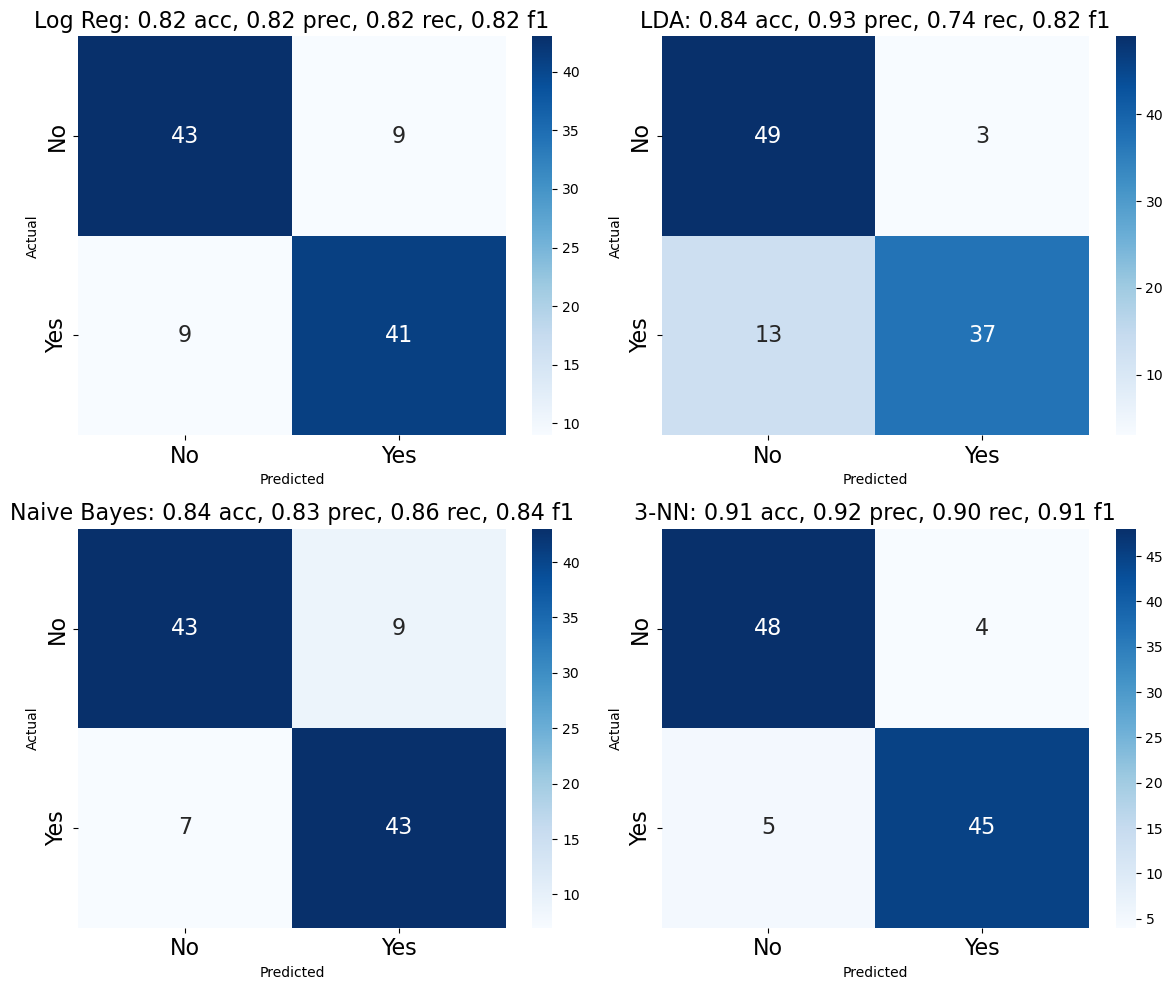

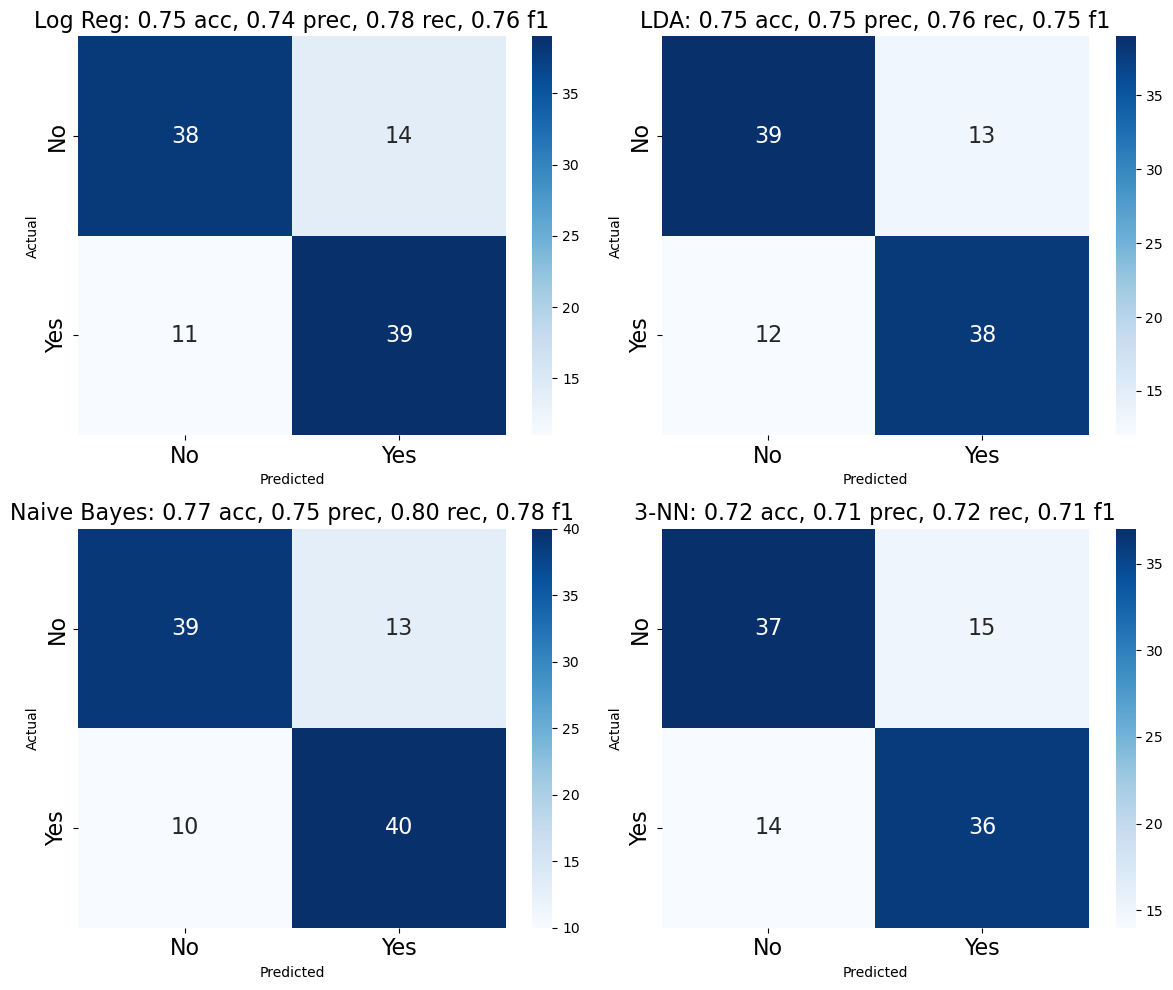

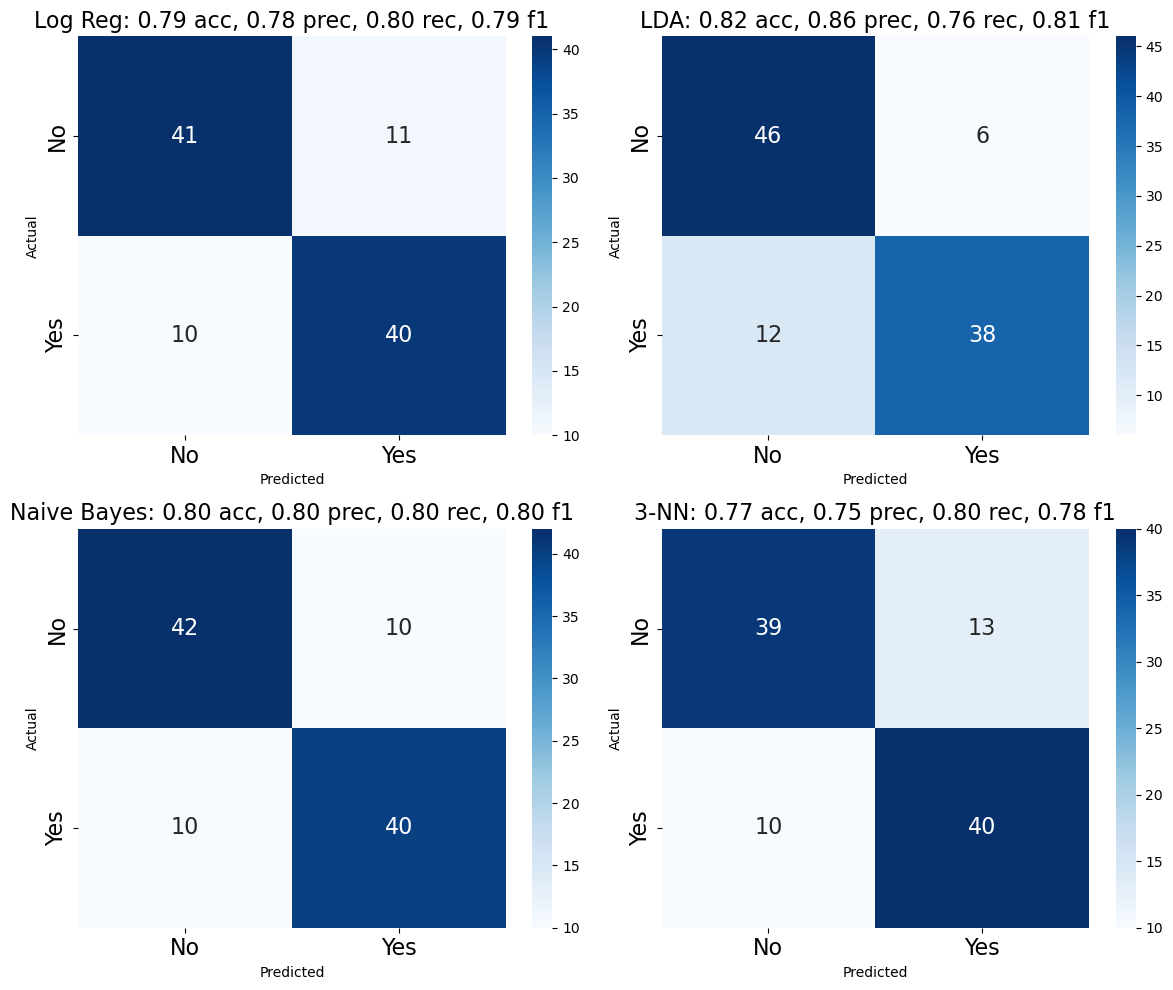

In [100]:
train_models_and_plot(X_all)
train_models_and_plot(X_socio)
train_models_and_plot(X_loc)

# Problem 5

In [ ]:
# 5a
Boston["medv"].mean()

np.float64(22.532806324110677)

In [ ]:
# 5b
Boston["medv"].std() / np.sqrt(Boston.shape[0])

np.float64(0.40886114749753505)

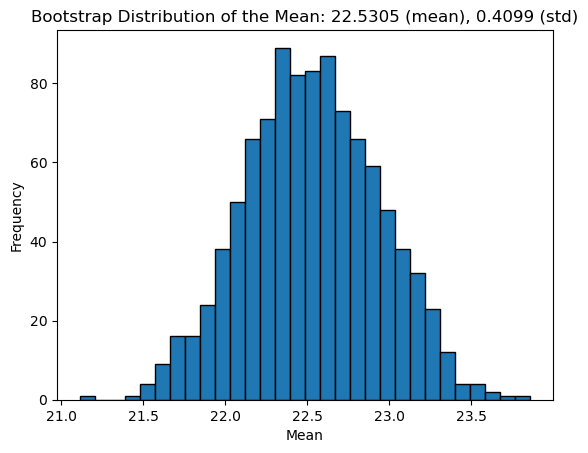

In [109]:
# 5c

bootstrap_means = []
for i in range(1000):
    bootstrap_sample = Boston["medv"].sample(n=Boston.shape[0], replace=True)
    bootstrap_mean = bootstrap_sample.mean()
    bootstrap_means.append(bootstrap_mean)
bootstrap_means = np.array(bootstrap_means)
plt.hist(bootstrap_means, bins=30, edgecolor='black')
plt.title(f"Bootstrap Distribution of the Mean: {bootstrap_means.mean():.4f} (mean), {bootstrap_means.std():.4f} (std)")
plt.xlabel(f"Mean")
plt.ylabel(f"Frequency")
plt.show()

In [ ]:
# 5e
Boston["medv"].median()

np.float64(21.2)

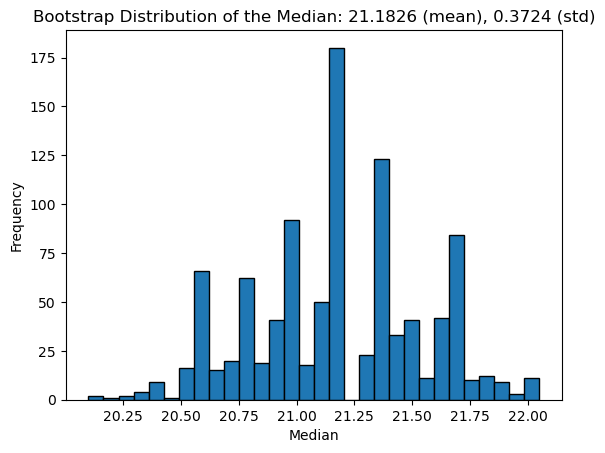

In [112]:
# 5f
bootstrap_medians = []
for i in range(1000):
    bootstrap_sample = Boston["medv"].sample(n=Boston.shape[0], replace=True)
    bootstrap_median = bootstrap_sample.median()
    bootstrap_medians.append(bootstrap_median)
bootstrap_medians = np.array(bootstrap_medians)
plt.hist(bootstrap_medians, bins=30, edgecolor='black')
plt.title(f"Bootstrap Distribution of the Median: {bootstrap_medians.mean():.4f} (mean), {bootstrap_medians.std():.4f} (std)")
plt.xlabel(f"Median")
plt.ylabel(f"Frequency")
plt.show()

In [113]:
# 5g
np.percentile(Boston["medv"], 10)

np.float64(12.75)

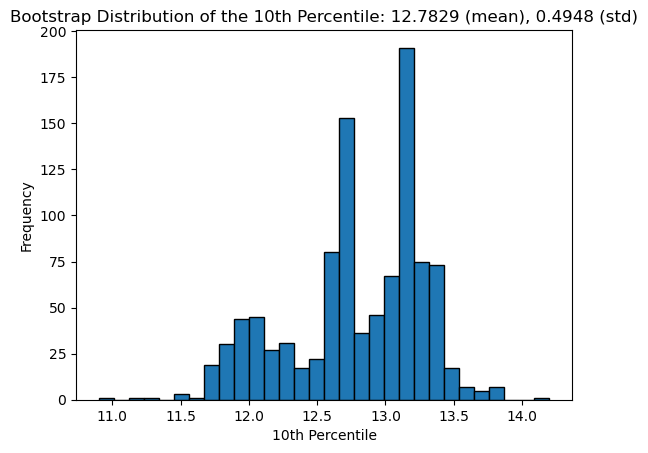

In [114]:
# 5h
bootstrap_percentiles = []
for i in range(1000):
    bootstrap_sample = Boston["medv"].sample(n=Boston.shape[0], replace=True)
    bootstrap_percentile = np.percentile(bootstrap_sample, 10)
    bootstrap_percentiles.append(bootstrap_percentile)
bootstrap_percentiles = np.array(bootstrap_percentiles)
plt.hist(bootstrap_percentiles, bins=30, edgecolor='black')
plt.title(f"Bootstrap Distribution of the 10th Percentile: {bootstrap_percentiles.mean():.4f} (mean), {bootstrap_percentiles.std():.4f} (std)")
plt.xlabel(f"10th Percentile")
plt.ylabel(f"Frequency")
plt.show()